# Análise de Volume e Persistência — Adalimumabe na Psoríase em SC (2020–2025)

Neste caderno vamos transformar a base higienizada de Psoríase (`apac_sc_psoriase_limpa.csv`) em **indicadores epidemiológicos e gráficos**.

### O que mudou em relação ao caderno anterior (`01_sql_consultas_sus.ipynb`)?
* Lá no caderno `01`, aprendemos a lógica do **SQL** (`JOIN`, `WHERE`, `GROUP BY`, `HAVING`).
* Aqui no caderno `02`, vamos usar **Python (`pandas`, `matplotlib` e `seaborn`)** sobre a base já **auditada** (sem os 6 pacientes com inconsistência de sexo/idade), cruzada com os nossos dois dicionários auxiliares (`SIGTAP` e `IBGE/SC`).

---

### Etapa 1: Colocando a base limpa e os dois dicionários na mesa (`pd.merge`)

Na nossa história da Central de Auditoria:
1. Abrimos o arquivo geral higienizado **`apac_sc_psoriase_limpa.csv`** (`94.145` fichas válidas de `4.425` pacientes).
2. Colocamos ao lado os dois dicionários da pasta `dicionarios/`:
   * **`sigtap_psoriase.csv`**: traduz códigos como `0604380135` para *Adalimumabe 40 mg injetável (Biossimilar B)*.
   * **`ibge_municipios_sc.csv`**: traduz códigos de 6 dígitos como `420540` para *Florianópolis* e sua *Mesorregião* em Santa Catarina.
3. Usamos **`pd.merge(..., how="left")`** (o equivalente em Python ao `LEFT JOIN` do SQL) para grampear essas informações em cada ficha e convertemos a coluna `AP_CMP` (`202001` a `202512`) para formato de data real (`pd.to_datetime`).

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Carrega a base higienizada e os dois dicionários auxiliares
df = pd.read_csv("apac_sc_psoriase_limpa.csv", dtype=str)
sigtap = pd.read_csv("dicionarios/sigtap_psoriase.csv", dtype=str)
ibge = pd.read_csv("dicionarios/ibge_municipios_sc.csv", dtype=str)

# 2. Cruzamento (LEFT JOIN em Python usando pd.merge)
df = df.merge(sigtap, left_on="AP_PRIPAL", right_on="codigo_sigtap", how="left")
df = df.merge(
    ibge[["codigo_ibge_6", "nome_municipio", "microrregiao", "mesorregiao"]],
    left_on="AP_MUNPCN",
    right_on="codigo_ibge_6",
    how="left"
)

# 3. Converte competência (AAAAMM) para data real e idade para número
df["data_competencia"] = pd.to_datetime(df["AP_CMP"], format="%Y%m")
df["ano"] = df["data_competencia"].dt.year
df["idade"] = pd.to_numeric(df["AP_NUIDADE"], errors="coerce")

print(f"Total de fichas carregadas: {len(df):,}")
print(f"Pacientes únicos na Psoríase (L40): {df['AP_CNSPCN'].nunique():,}")
df[["AP_CMP", "AP_CNSPCN", "principio_ativo", "nome_municipio", "mesorregiao"]].head(5)

Total de fichas carregadas: 94,145
Pacientes únicos na Psoríase (L40): 4,425


,AP_CMP,AP_CNSPCN,principio_ativo,nome_municipio,mesorregiao
0,202001,700108046696529,Acitretina,Balneário Camboriú,Vale do Itajaí
1,202001,700529239492068,Acitretina,Porto Belo,Vale do Itajaí
2,202001,700621864365564,Acitretina,Jaraguá do Sul,Norte Catarinense
3,202001,700255246416891,Metotrexato,Turvo,Sul Catarinense
4,202001,700751657290400,Metotrexato,Chapecó,Oeste Catarinense


---

### Etapa 2: Volume de Dispensações na Psoríase em SC (2020 a 2025)

Antes de olhar só para o Adalimumabe, o auditor quer enxergar o tamanho dele dentro do protocolo completo de Psoríase (`L40`) em Santa Catarina:
* Quantas fichas (dispensações) cada medicamento teve nos 6 anos?
* Como evoluiu o volume anual de dispensações de **Adalimumabe** em comparação com os outros medicamentos de 2020 a 2025?

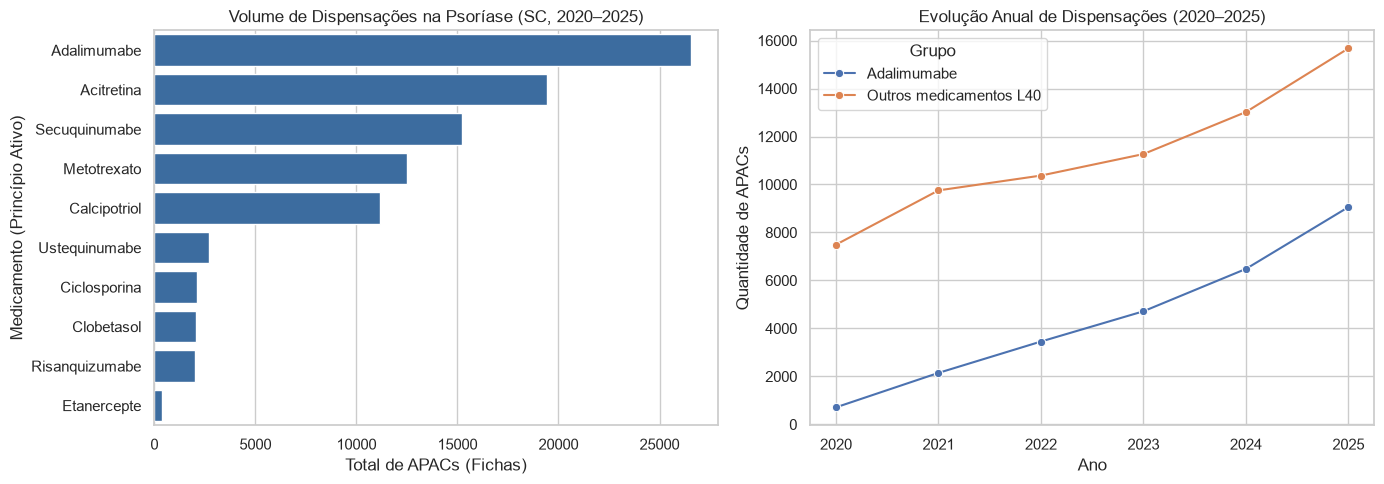

In [7]:
vol_med = df["principio_ativo"].value_counts().reset_index()
vol_med.columns = ["principio_ativo", "total_dispensacoes"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Ranking de volume por medicamento
sns.barplot(data=vol_med, y="principio_ativo", x="total_dispensacoes", ax=axes[0], color="#2b6cb0")
axes[0].set_title("Volume de Dispensações na Psoríase (SC, 2020–2025)")
axes[0].set_xlabel("Total de APACs (Fichas)")
axes[0].set_ylabel("Medicamento (Princípio Ativo)")

# Gráfico 2: Evolução anual Adalimumabe vs Outros Medicamentos
df["grupo_adali"] = df["principio_ativo"].apply(
    lambda x: "Adalimumabe" if x == "Adalimumabe" else "Outros medicamentos L40"
)
evol_anual = df.groupby(["ano", "grupo_adali"]).size().reset_index(name="dispensacoes")
sns.lineplot(data=evol_anual, x="ano", y="dispensacoes", hue="grupo_adali", marker="o", ax=axes[1])
axes[1].set_title("Evolução Anual de Dispensações (2020–2025)")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Quantidade de APACs")
axes[1].legend(title="Grupo")

plt.tight_layout()
plt.show()

---

### Etapa 3: Itinerário e Persistência no Adalimumabe (`pd.to_datetime` e `.dt.days`)

Agora filtramos apenas as fichas de **Adalimumabe** (`1.477` pacientes únicos válidos) e fechamos a "pasta" de cada paciente (`groupby("AP_CNSPCN")`) para calcular dois indicadores clássicos de farmacoepidemiologia:

1. **`total_meses_dispensados`**: quantos meses diferentes o paciente realmente foi buscar o medicamento (`nunique` de `AP_CMP`).
2. **`dias_acompanhamento`**: diferença em dias entre a primeira retirada (`min`) e a última retirada (`max`), usando `(data_fim - data_inicio).dt.days`.

In [8]:
df_adali = df[df["principio_ativo"] == "Adalimumabe"].copy()

coorte_adali = df_adali.sort_values("data_competencia").groupby("AP_CNSPCN").agg(
    cid10=("AP_CIDPRI", "first"),
    sexo=("AP_SEXO", "first"),
    idade_inicial=("idade", "min"),
    mesorregiao=("mesorregiao", "first"),
    data_inicio=("data_competencia", "min"),
    data_fim=("data_competencia", "max"),
    total_meses_dispensados=("AP_CMP", "nunique"),
    n_apacs=("AP_AUTORIZ", "count")
).reset_index()

coorte_adali["dias_acompanhamento"] = (coorte_adali["data_fim"] - coorte_adali["data_inicio"]).dt.days

print(f"Pacientes válidos em uso de Adalimumabe: {len(coorte_adali):,}")
print(f"Média de meses dispensados: {coorte_adali['total_meses_dispensados'].mean():.1f} meses")
print(f"Mediana de meses dispensados: {coorte_adali['total_meses_dispensados'].median():.1f} meses")
print(f"Mediana de acompanhamento: {coorte_adali['dias_acompanhamento'].median():.0f} dias")

coorte_adali[["total_meses_dispensados", "dias_acompanhamento", "idade_inicial"]].describe().round(1)

Pacientes válidos em uso de Adalimumabe: 1,477
Média de meses dispensados: 18.0 meses
Mediana de meses dispensados: 12.0 meses
Mediana de acompanhamento: 365 dias


,total_meses_dispensados,dias_acompanhamento,idade_inicial
count,1477.0,1477.0,1477.0
mean,18.0,541.3,47.0
std,15.7,500.2,14.3
min,1.0,0.0,15.0
25%,6.0,153.0,36.0
50%,12.0,365.0,47.0
75%,25.0,792.0,57.0
max,72.0,2161.0,93.0


---

### Etapa 4: Distribuição por Faixas de Persistência (de 3 até 72 meses)

Aqui reproduzimos em Python a mesma divisão em **9 faixas de meses** que fizemos no SQL, calculando quantos pacientes e qual o percentual (`%`) permaneceu em cada faixa de tempo.

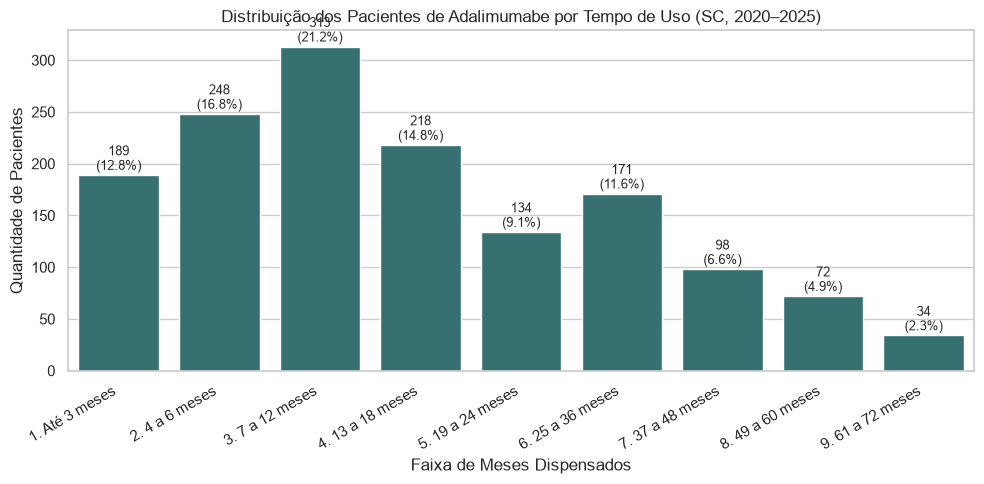

,faixa_meses,pacientes,percentual_%
0,1. Até 3 meses,189,12.8
1,2. 4 a 6 meses,248,16.8
2,3. 7 a 12 meses,313,21.2
3,4. 13 a 18 meses,218,14.8
4,5. 19 a 24 meses,134,9.1
5,6. 25 a 36 meses,171,11.6
6,7. 37 a 48 meses,98,6.6
7,8. 49 a 60 meses,72,4.9
8,9. 61 a 72 meses,34,2.3


In [9]:
bins = [0, 3, 6, 12, 18, 24, 36, 48, 60, 72]
labels = [
    "1. Até 3 meses", "2. 4 a 6 meses", "3. 7 a 12 meses",
    "4. 13 a 18 meses", "5. 19 a 24 meses", "6. 25 a 36 meses",
    "7. 37 a 48 meses", "8. 49 a 60 meses", "9. 61 a 72 meses"
]
coorte_adali["faixa_meses"] = pd.cut(coorte_adali["total_meses_dispensados"], bins=bins, labels=labels)

resumo_faixas = coorte_adali["faixa_meses"].value_counts().sort_index().reset_index()
resumo_faixas.columns = ["faixa_meses", "pacientes"]
resumo_faixas["percentual_%"] = (resumo_faixas["pacientes"] / len(coorte_adali) * 100).round(1)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=resumo_faixas, x="faixa_meses", y="pacientes", color="#2c7a7b")
for i, row in resumo_faixas.iterrows():
    ax.text(i, row["pacientes"] + 5, f"{row['pacientes']}\n({row['percentual_%']}%)", ha="center", fontsize=9)
plt.title("Distribuição dos Pacientes de Adalimumabe por Tempo de Uso (SC, 2020–2025)")
plt.xlabel("Faixa de Meses Dispensados")
plt.ylabel("Quantidade de Pacientes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

resumo_faixas

---

### Etapa 5: Perfil Demográfico (Sexo) e Regional (Mesorregiões de SC)

Por fim, o auditor cruza os dados da coorte de Adalimumabe com o sexo dos pacientes e com as **mesorregiões de Santa Catarina** (que vieram do dicionário `ibge_municipios_sc.csv`) para responder:
* O volume de pacientes e a mediana de persistência mudam entre homens e mulheres?
* Quais mesorregiões de Santa Catarina concentram mais pacientes em uso de Adalimumabe para Psoríase?

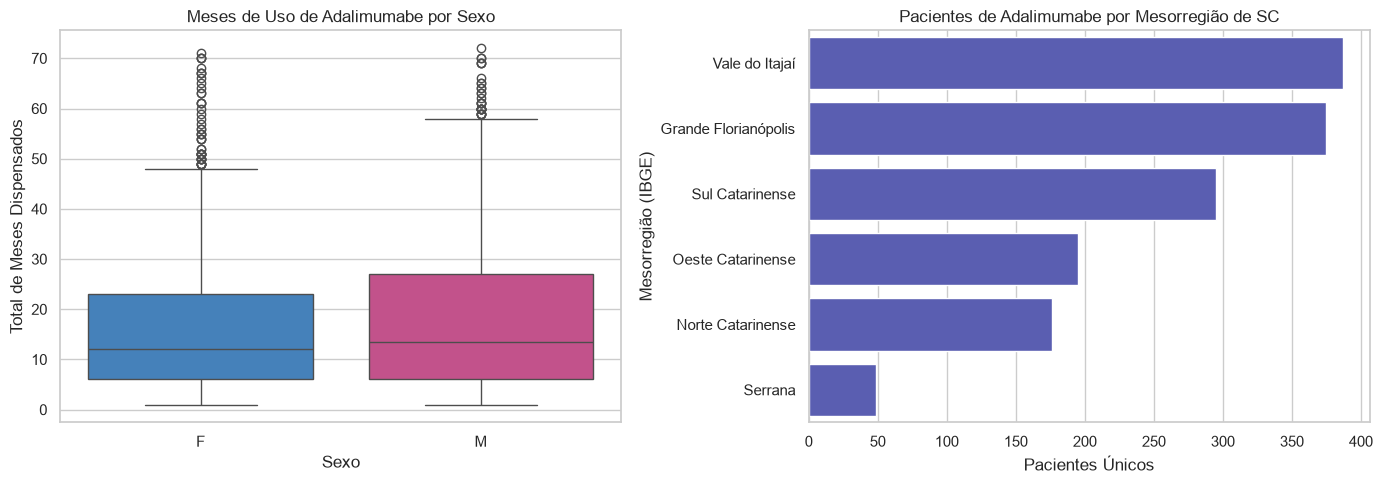

,pacientes,mediana_meses,media_meses
mesorregiao,,,
Vale do Itajaí,387,12.0,18.7
Grande Florianópolis,375,12.0,17.8
Sul Catarinense,295,12.0,16.5
Oeste Catarinense,195,14.0,18.4
Norte Catarinense,176,13.5,18.1
Serrana,49,15.0,20.8


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Persistência (meses) por Sexo
sns.boxplot(data=coorte_adali, x="sexo", y="total_meses_dispensados", hue="sexo", palette=["#3182ce", "#d53f8c"], legend=False, ax=axes[0])
axes[0].set_title("Meses de Uso de Adalimumabe por Sexo")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Total de Meses Dispensados")

# Gráfico 2: Pacientes por Mesorregião de SC
regiao_df = coorte_adali["mesorregiao"].value_counts().reset_index()
regiao_df.columns = ["mesorregiao", "pacientes"]
sns.barplot(data=regiao_df, y="mesorregiao", x="pacientes", ax=axes[1], color="#4c51bf")
axes[1].set_title("Pacientes de Adalimumabe por Mesorregião de SC")
axes[1].set_xlabel("Pacientes Únicos")
axes[1].set_ylabel("Mesorregião (IBGE)")

plt.tight_layout()
plt.show()

coorte_adali.groupby("mesorregiao").agg(
    pacientes=("AP_CNSPCN", "count"),
    mediana_meses=("total_meses_dispensados", "median"),
    media_meses=("total_meses_dispensados", "mean")
).round(1).sort_values("pacientes", ascending=False)

---

### Etapa 6: Filtro Interativo por Tipo de Psoríase (`AP_CIDPRI`)

Na nossa base de Santa Catarina existem **4 tipos de Psoríase** registrados no campo `AP_CIDPRI`:
* **`L400`**: Psoríase vulgar
* **`L401`**: Psoríase pustulosa generalizada
* **`L404`**: Psoríase gutata
* **`L408`**: Outras formas de psoríase

A célula abaixo permite **filtrar por tipo de Psoríase** trocando apenas o código na variável `TIPO_PSORIASE` (`"TODAS"`, `"L400"`, `"L401"`, `"L404"` ou `"L408"`). Ao rodar a célula, o Python filtra `df` automaticamente e atualiza:
1. O **volume de dispensações por medicamento** (para ver quais medicamentos são mais usados naquele subtipo).
2. A **distribuição de persistência do Adalimumabe** (quantos meses os pacientes daquele subtipo permanecem em tratamento).

In [ ]:
# Escolha o tipo de Psoríase trocando o código abaixo:
# Opções: "TODAS", "L400", "L401", "L404", "L408"
TIPO_PSORIASE = "L400"

nomes_cid = {
    "TODAS": "Todas as Psoríases (L400, L401, L404, L408)",
    "L400": "L400 — Psoríase vulgar",
    "L401": "L401 — Psoríase pustulosa generalizada",
    "L404": "L404 — Psoríase gutata",
    "L408": "L408 — Outras formas de psoríase",
}

df_sub = df if TIPO_PSORIASE == "TODAS" else df[df["AP_CIDPRI"] == TIPO_PSORIASE]
df_sub_adali = df_sub[df_sub["principio_ativo"] == "Adalimumabe"]

print(f"Filtro: {nomes_cid.get(TIPO_PSORIASE, TIPO_PSORIASE)}")
print(f"Fichas totais: {len(df_sub):,} | Pacientes únicos: {df_sub['AP_CNSPCN'].nunique():,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Medicamentos usados nesse tipo de Psoríase
vol_sub = df_sub["principio_ativo"].value_counts().reset_index()
vol_sub.columns = ["principio_ativo", "dispensacoes"]
sns.barplot(data=vol_sub, y="principio_ativo", x="dispensacoes", ax=axes[0], color="#2b6cb0")
axes[0].set_title(f"Medicamentos Dispensados ({TIPO_PSORIASE})")
axes[0].set_xlabel("Total de APACs")
axes[0].set_ylabel("Medicamento")

# Gráfico 2: Persistência do Adalimumabe nesse tipo de Psoríase
if df_sub_adali.empty:
    axes[1].text(0.5, 0.5, "Sem dispensações de Adalimumabe neste CID", ha="center", va="center")
    axes[1].set_title(f"Persistência do Adalimumabe ({TIPO_PSORIASE})")
else:
    coorte_sub = df_sub_adali.groupby("AP_CNSPCN")["AP_CMP"].nunique().reset_index(name="meses")
    bins = [0, 3, 6, 12, 18, 24, 36, 48, 60, 72]
    labels = ["<=3", "4-6", "7-12", "13-18", "19-24", "25-36", "37-48", "49-60", "61-72"]
    coorte_sub["faixa"] = pd.cut(coorte_sub["meses"], bins=bins, labels=labels)
    faixas_sub = coorte_sub["faixa"].value_counts().sort_index().reset_index()
    faixas_sub.columns = ["faixa", "pacientes"]
    sns.barplot(data=faixas_sub, x="faixa", y="pacientes", ax=axes[1], color="#2c7a7b")
    axes[1].set_title(f"Adalimumabe: {len(coorte_sub)} pacientes | Mediana: {coorte_sub['meses'].median():.1f} meses")
    axes[1].set_xlabel("Faixa de Meses Dispensados")
    axes[1].set_ylabel("Pacientes")

plt.tight_layout()
plt.show()